# Task 1 · Heart rate from an optical signal

**MPHY0058 | Problem 1, optical sensor.** The recording contains light intensity reflected from a finger. The aim is to identify its repeating pulse and estimate the rate over the recording.

The figures and numerical outputs below are saved in this notebook. To run the analysis again, put the original `heart_beat_signal.csv` inside the adjacent `data` folder and run all cells with Python 3, NumPy and Matplotlib.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

source = Path("data/heart_beat_signal.csv")
output = Path("task1_outputs")
output.mkdir(exist_ok=True)

# The course CSV has no header. Column 1 is time in seconds.
time, amplitude = np.loadtxt(source, delimiter=",", unpack=True)
if not np.all(np.isfinite([time, amplitude])) or np.any(np.diff(time) <= 0):
    raise ValueError("Inspect the CSV for missing values or out-of-order timestamps.")

n = len(time)
duration = time[-1] - time[0]
fs = (n - 1) / duration
print(f"{n} samples | {time[0]:.6f} to {time[-1]:.3f} s")
print(f"Recording span: {duration:.3f} s | Mean sampling rate: {fs:.3f} Hz")

913 samples | 0.033367 to 30.464 s
Recording span: 30.431 s | Mean sampling rate: 29.970 Hz


## 1.1 · Plot the original optical signal

Each point uses the timestamp and amplitude supplied in the CSV. The amplitude unit is unspecified. Periodic downward excursions are visible alongside slower changes in the baseline.

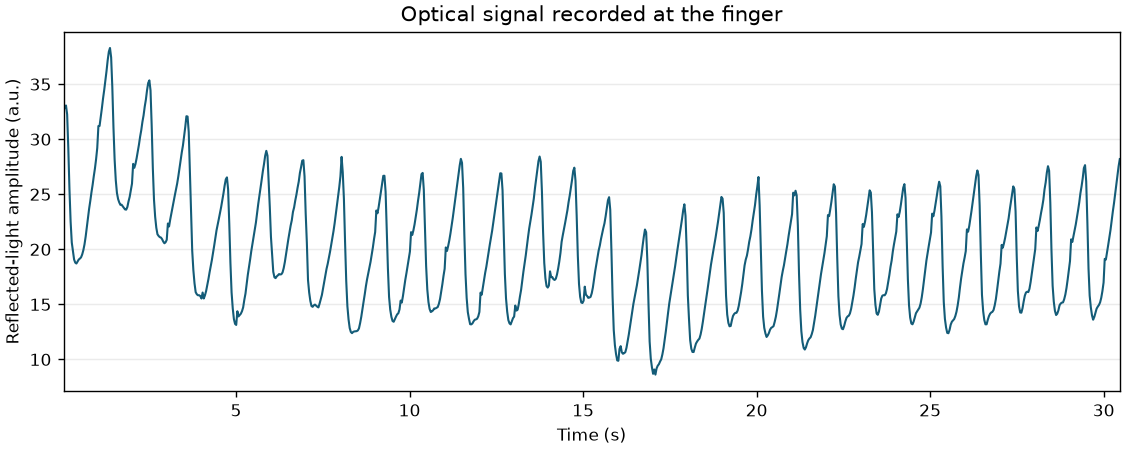

In [2]:
fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
ax.plot(time, amplitude, color="#145C78", linewidth=1.2)
ax.set(title="Optical signal recorded at the finger", xlabel="Time (s)",
       ylabel="Reflected-light amplitude (a.u.)", xlim=(time[0], time[-1]))
ax.grid(axis="y", alpha=0.25)
fig.savefig(output / "task1_raw_signal.png", dpi=200)
plt.show()

## 1.2 · Estimate heart rate using an FFT

The FFT assumes equal time steps. We check the timestamps against an equal-spaced grid, then use linear interpolation to put the signal on that grid. Removing the mean suppresses the constant light level. A Hann window tapers the two ends of the recording to reduce spectral leakage.

For this recording we search **0.5–3.5 Hz (30–210 bpm)**, an analysis choice that excludes slow baseline changes and allows a broad range of candidate rates. A spectral peak can be a harmonic, so we also examine the pulse period in the time domain.

In [3]:
uniform_time = np.linspace(time[0], time[-1], n)
uniform_signal = np.interp(uniform_time, time, amplitude)
max_offset = np.max(np.abs(uniform_time - time))
print(f"Maximum timestamp offset from equal spacing: {1000 * max_offset:.3f} ms")

centred = uniform_signal - uniform_signal.mean()
window = np.hanning(n)
frequency = np.fft.rfftfreq(n, d=1 / fs)
# Divide by the window sum to express the one-sided spectrum in amplitude units.
spectrum = np.abs(np.fft.rfft(centred * window)) / window.sum()
spectrum[1:] *= 2
if n % 2 == 0:
    spectrum[-1] /= 2  # The Nyquist bin only occurs once for an even sample count.

low_hz, high_hz = 0.5, 3.5
in_band = np.flatnonzero((frequency >= low_hz) & (frequency <= high_hz))
peak = in_band[np.argmax(spectrum[in_band])]
peak_hz = frequency[peak]
heart_rate = 60 * peak_hz
bin_hz = fs / n
print(f"Peak: {peak_hz:.4f} Hz | Estimated heart rate: {heart_rate:.1f} bpm")
print(f"FFT bin spacing: {bin_hz:.4f} Hz ({60 * bin_hz:.2f} bpm)")

Maximum timestamp offset from equal spacing: 0.711 ms
Peak: 0.9191 Hz | Estimated heart rate: 55.1 bpm
FFT bin spacing: 0.0328 Hz (1.97 bpm)


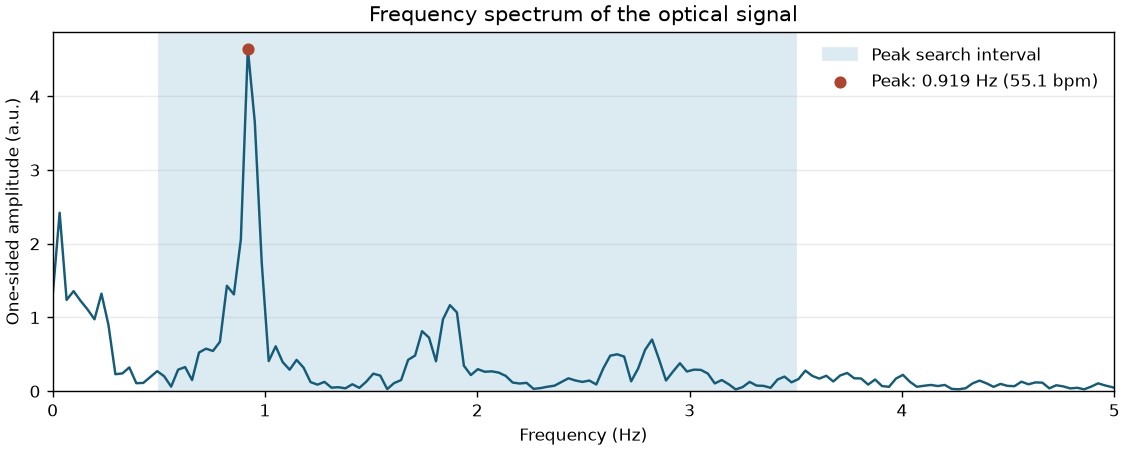

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
ax.axvspan(low_hz, high_hz, color="#DBEBF1", label="Peak search interval")
ax.plot(frequency, spectrum, color="#145C78", linewidth=1.4)
ax.scatter(peak_hz, spectrum[peak], color="#AD442D", zorder=4,
           label=f"Peak: {peak_hz:.3f} Hz ({heart_rate:.1f} bpm)")
ax.set(xlim=(0, 5), ylim=(0, None), xlabel="Frequency (Hz)",
       ylabel="One-sided amplitude (a.u.)", title="Frequency spectrum of the optical signal")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.savefig(output / "task1_fft_spectrum.png", dpi=200)
plt.show()

## Check the pulse period

Autocorrelation compares the waveform with a time-shifted copy of itself. A local maximum indicates a delay at which pulses line up. We exclude zero lag and look for the strongest local maximum over periods corresponding to the same search interval.

In [5]:
correlation = np.correlate(centred, centred, mode="full")[n - 1:]
lags = np.arange(n) / fs
maxima = np.flatnonzero((correlation[1:-1] > correlation[:-2]) &
                        (correlation[1:-1] >= correlation[2:])) + 1
possible = maxima[(lags[maxima] >= 1 / high_hz) & (lags[maxima] <= 1 / low_hz)]
if not possible.size:
    raise ValueError("No repeat period found within the specified range.")
repeat_lag = possible[np.argmax(correlation[possible])]
period = lags[repeat_lag]
check_rate = 60 / period
print(f"Repeat period: {period:.3f} s ({repeat_lag} samples)")
print(f"Time-domain estimate: {check_rate:.1f} bpm")
print(f"Difference from FFT estimate: {abs(check_rate - heart_rate):.1f} bpm")

np.savetxt(output / "task1_spectrum.csv", np.column_stack((frequency, spectrum)),
           delimiter=",", header="frequency_hz,one_sided_amplitude", comments="")

Repeat period: 1.068 s (32 samples)
Time-domain estimate: 56.2 bpm
Difference from FFT estimate: 1.0 bpm


## Result and interpretation

The strongest in-band peak occurs at **0.9191 Hz**, giving an estimated **55.1 bpm** over **30.43 s**. The waveform repeats at a delay of **1.068 s**, corresponding to **56.2 bpm**. The two estimates differ by about **1.0 bpm**, less than the **1.97 bpm** spacing between adjacent FFT bins. A smaller peak near **1.87 Hz** lies close to twice the main frequency, consistent with a harmonic of the nonsinusoidal pulse.

The short recording limits how finely the FFT separates nearby rates. Both calculations use the same optical recording. An independently measured, simultaneous reference heart rate would be needed to assess absolute accuracy.

**AI use.** OpenAI ChatGPT (GPT-6.2-astra, Codex) assisted in writing and running the Python analysis, generating the figures and drafting the interpretation. Record any further use and your group's own checks in the final submission.